# 003 - Rock vs Mines - Pytorch  

## Admin 

In [17]:
# Import Libraries 

import pandas as pd 
import numpy as np 

# train test split 
from sklearn.model_selection import train_test_split

# import model 
import torch as tr 
import torch.nn as nn
import torch.optim as optim

# data handling 
from torch.utils.data import Dataset, DataLoader

# plotting 
import matplotlib.pyplot as plt 


In [2]:
# set the seed 
model_seed = 122

In [3]:
# select tensor processing unit 
if tr.cuda.is_available(): 
    device = 'gpu'
else: 
    device = 'cpu'

print(f'Device: {device}')

Device: cpu


In [4]:
class CustomBinaryDataset(Dataset):
    def __init__(self, X, y):
        self.X = tr.tensor(X, dtype=tr.float32)
        self.y = tr.tensor(y, dtype=tr.float32).unsqueeze(1) # Add a dimension for binary output

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

## Data 

In [5]:
fileIn = "C:\\Users\\patri\\OneDrive\\Projects\\Quantum_IBM\\R_v_M\\data\\sonar.all-data.csv"
df = pd.read_csv(fileIn)
df.head()

,Freq_1,Freq_2,Freq_3,Freq_4,Freq_5,Freq_6,Freq_7,Freq_8,Freq_9,Freq_10,...,Freq_52,Freq_53,Freq_54,Freq_55,Freq_56,Freq_57,Freq_58,Freq_59,Freq_60,Label
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,0
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,0
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,0
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,0
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,0


In [6]:
# find shape
df.shape

(208, 61)

In [7]:
# get the X,y vectors 
X = df.iloc[:, :60]
y = df.iloc[:, -1]

In [8]:
# check results 
print("X: ", X.shape)
print("y: ", y.shape)

X:  (208, 60)
y:  (208,)


In [9]:
# train/test split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=model_seed)

In [10]:
# validate split 
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (166, 60)
Shape of X_test: (42, 60)
Shape of y_train: (166,)
Shape of y_test: (42,)


In [11]:
# first to numpy arrays 
X_train = X_train.to_numpy()
X_test = X_test.to_numpy() 
y_train = y_train.to_numpy() 
y_test = y_test.to_numpy() 

In [21]:
# create the data loadera 

# training set 
train_dataset = CustomBinaryDataset(X_train, y_train)
train_dataloader = DataLoader(train_dataset, batch_size=16, shuffle=True)

# training set 
test_dataset = CustomBinaryDataset(X_test, y_test)
test_dataloader = DataLoader(test_dataset, batch_size=16, shuffle=False)


## Model

In [13]:

class BinaryClassifier(nn.Module):
    def __init__(self, input_size = 60):
        super(BinaryClassifier, self).__init__()
        self.layer1 = nn.Linear(input_size, 120)
        self.relu = nn.ReLU()
        self.output_layer = nn.Linear(120, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.layer1(x)
        x = self.relu(x)
        x = self.output_layer(x)
        x = self.sigmoid(x)
        return x

In [14]:
# instantiate the model 
# 5. Initialize the model, loss function, and optimizer
input_size = X_train.shape[1]
model = BinaryClassifier(input_size)
criterion = nn.BCELoss() # Binary Cross-Entropy Loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [15]:
epochs = 200 
losses = [] 

num_epochs = 50
for epoch in range(epochs):
    for inputs, labels in train_dataloader:
        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')
        losses.append([epoch + 1, loss.item()])
    

Epoch [10/50], Loss: 0.3180
Epoch [20/50], Loss: 0.7369
Epoch [30/50], Loss: 0.2213
Epoch [40/50], Loss: 0.2495
Epoch [50/50], Loss: 0.2973
Epoch [60/50], Loss: 0.5264
Epoch [70/50], Loss: 0.0498
Epoch [80/50], Loss: 0.0375
Epoch [90/50], Loss: 0.0218
Epoch [100/50], Loss: 0.0284
Epoch [110/50], Loss: 0.0060
Epoch [120/50], Loss: 0.0055
Epoch [130/50], Loss: 0.0093
Epoch [140/50], Loss: 0.0066
Epoch [150/50], Loss: 0.0024
Epoch [160/50], Loss: 0.0017
Epoch [170/50], Loss: 0.0017
Epoch [180/50], Loss: 0.0039
Epoch [190/50], Loss: 0.0011
Epoch [200/50], Loss: 0.0003


## Plot

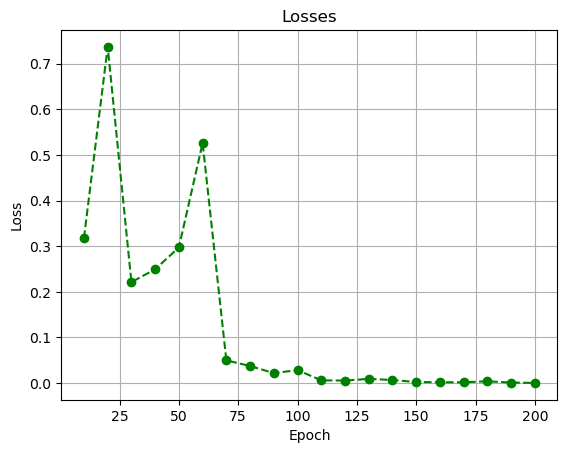

In [20]:
# Extract x and y coordinates
df = pd.DataFrame(losses, columns=['epoch', 'loss'])
  
# Plotting
plt.plot(df['epoch'], df['loss'], 'go--') 
plt.title("Losses")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

## Evaluation 

In [23]:
model.eval() # Set model to evaluation mode
with tr.no_grad():
    total_correct = 0
    total_samples = 0
    for inputs, labels in test_dataloader:
        outputs = model(inputs)
        predicted = (outputs > 0.5).float() # Threshold at 0.5 for binary prediction
        total_samples += labels.size(0)
        total_correct += (predicted == labels).sum().item()

    accuracy = (total_correct / total_samples) * 100 
    print(f'Accuracy on training data: {accuracy:.2f}%')

Accuracy on training data: 76.19%
